#Research question:
 Can lifestyle habits (study, sleep, screen time, stress, diet, exercise) predict `Health_Risk` (Low / Medium / High)?


## 1. Imports and settings

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

TARGET = "Health_Risk"
ID_COL = "id"
NUM_COLS = ["Study_Hours", "Sleep_Hours", "Screen_Time", "Exercise_Hours"]
CAT_COLS = ["Stress_Level", "Diet_Quality"]
ORDER = {
    "Stress_Level": ["Low", "Medium", "High", "Very High"],
    "Diet_Quality": ["Poor", "Average", "Good", "Excellent"],
    TARGET: ["Low", "Medium", "High"],
}

## 2. Load the data
Upload both files when prompted. (If you keep them in Google Drive instead, see the commented option.)

In [ ]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("train:", train.shape)
print("test: ", test.shape)
display(train.head())
display(test.head())

train: (4000, 8)
test:  (1000, 7)


,id,Study_Hours,Sleep_Hours,Screen_Time,Stress_Level,Diet_Quality,Exercise_Hours,Health_Risk
0,1501,6.7,3.6,10.7,Very High,Excellent,0.7,High
1,2586,1.0,5.9,3.3,Very High,Poor,1.6,Low
2,2653,0.7,8.7,6.0,High,Poor,4.3,Medium
3,1055,4.9,6.5,4.8,High,Average,2.8,Low
4,705,13.9,4.9,7.5,Medium,Good,4.9,Low


,id,Study_Hours,Sleep_Hours,Screen_Time,Stress_Level,Diet_Quality,Exercise_Hours
0,3,8.4,5.4,7.7,Very High,Average,3.3
1,4,2.2,9.1,6.2,Low,Average,2.4
2,5,2.2,3.6,10.5,Very High,Excellent,3.7
3,9,9.9,6.0,9.4,High,Good,1.2
4,16,4.3,3.3,1.1,Low,Excellent,3.7


## 3. Column overview

In [ ]:
overview = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "num_unique_train": train.nunique(),
    "in_test": [c in test.columns for c in train.columns],
    "example": train.iloc[0],
})
display(overview)

,dtype,num_unique_train,in_test,example
id,int64,4000,True,1501
Study_Hours,float64,141,True,6.7
Sleep_Hours,float64,71,True,3.6
Screen_Time,float64,111,True,10.7
Stress_Level,object,4,True,Very High
Diet_Quality,object,4,True,Excellent
Exercise_Hours,float64,51,True,0.7
Health_Risk,object,3,False,High


## 4. Missing values and duplicates

In [ ]:
for name, df in [("TRAIN", train), ("TEST", test)]:
    feat_cols = [c for c in df.columns if c != ID_COL]
    miss = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean() * 100).round(2)})
    display(miss)
    print("Fully duplicated rows:      ", df.duplicated().sum())
    print("Duplicates ignoring id:     ", df.duplicated(subset=feat_cols).sum())
    print("Duplicate ids:              ", df[ID_COL].duplicated().sum())
    print("id range:                   ", df[ID_COL].min(), "-", df[ID_COL].max())
    print()


,missing,missing_%
id,0,0.0
Study_Hours,0,0.0
Sleep_Hours,0,0.0
Screen_Time,0,0.0
Stress_Level,0,0.0
Diet_Quality,0,0.0
Exercise_Hours,0,0.0
Health_Risk,0,0.0


Fully duplicated rows:       0
Duplicates ignoring id:      0
Duplicate ids:               0
id range:                    0 - 4999



,missing,missing_%
id,0,0.0
Study_Hours,0,0.0
Sleep_Hours,0,0.0
Screen_Time,0,0.0
Stress_Level,0,0.0
Diet_Quality,0,0.0
Exercise_Hours,0,0.0


Fully duplicated rows:       0
Duplicates ignoring id:      0
Duplicate ids:               0
id range:                    3 - 4994



## 5. Target distribution and class imbalance (train)

,count,share_%
Health_Risk,,
Low,2610,65.25
Medium,1064,26.60
High,326,8.15


Imbalance ratio (largest / smallest): 8.01
Majority-class baseline accuracy:     0.6525


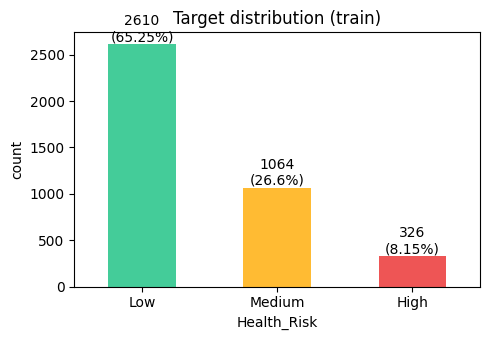

In [ ]:
counts = train[TARGET].value_counts().reindex(ORDER[TARGET])
share = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"count": counts, "share_%": share}))

print("Imbalance ratio (largest / smallest):", round(counts.max() / counts.min(), 2))
print("Majority-class baseline accuracy:    ", round(counts.max() / counts.sum(), 4))

ax = counts.plot.bar(color=["#4c9", "#fb3", "#e55"], figsize=(5, 3.5))
ax.set_title("Target distribution (train)")
ax.set_ylabel("count")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n({share.iloc[i]}%)", ha="center", va="bottom")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Numeric features

In [ ]:
for name, df in [("TRAIN", train), ("TEST", test)]:
    print(f"{name}")
    display(df[NUM_COLS].describe().T.round(2))
    print("Skew:", df[NUM_COLS].skew().round(2).to_dict())

# Outliers by the 1.5*IQR rule, using train's fences for both sets
rows = []
for c in NUM_COLS:
    q1, q3 = train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({
        "feature": c,
        "train_outliers": int(((train[c] < lo) | (train[c] > hi)).sum()),
        "test_outliers": int(((test[c] < lo) | (test[c] > hi)).sum()),
        "train_zeros": int((train[c] == 0).sum()),
        "test_zeros": int((test[c] == 0).sum()),
    })
display(pd.DataFrame(rows).set_index("feature"))

print("Correlation between numeric features (train):")
display(train[NUM_COLS].corr().round(3))

TRAIN


,count,mean,std,min,25%,50%,75%,max
Study_Hours,4000.0,6.91,4.06,0.0,3.4,6.9,10.4,14.0
Sleep_Hours,4000.0,6.45,2.00,3.0,4.7,6.4,8.1,10.0
Screen_Time,4000.0,6.51,3.21,1.0,3.7,6.5,9.4,12.0
Exercise_Hours,4000.0,2.56,1.43,0.0,1.4,2.6,3.8,5.0


Skew: {'Study_Hours': 0.02, 'Sleep_Hours': 0.05, 'Screen_Time': 0.0, 'Exercise_Hours': -0.05}
TEST


,count,mean,std,min,25%,50%,75%,max
Study_Hours,1000.0,7.13,4.02,0.0,3.68,7.3,10.60,14.0
Sleep_Hours,1000.0,6.41,2.02,3.0,4.70,6.4,8.10,10.0
Screen_Time,1000.0,6.52,3.17,1.0,3.80,6.4,9.33,12.0
Exercise_Hours,1000.0,2.49,1.49,0.0,1.20,2.5,3.80,5.0


Skew: {'Study_Hours': -0.04, 'Sleep_Hours': 0.05, 'Screen_Time': 0.03, 'Exercise_Hours': 0.03}


,train_outliers,test_outliers,train_zeros,test_zeros
feature,,,,
Study_Hours,0,0,10,3
Sleep_Hours,0,0,0,0
Screen_Time,0,0,0,0
Exercise_Hours,0,0,33,14


Correlation between numeric features (train):


,Study_Hours,Sleep_Hours,Screen_Time,Exercise_Hours
Study_Hours,1.000,0.002,-0.012,-0.010
Sleep_Hours,0.002,1.000,-0.016,0.005
Screen_Time,-0.012,-0.016,1.000,-0.030
Exercise_Hours,-0.010,0.005,-0.030,1.000


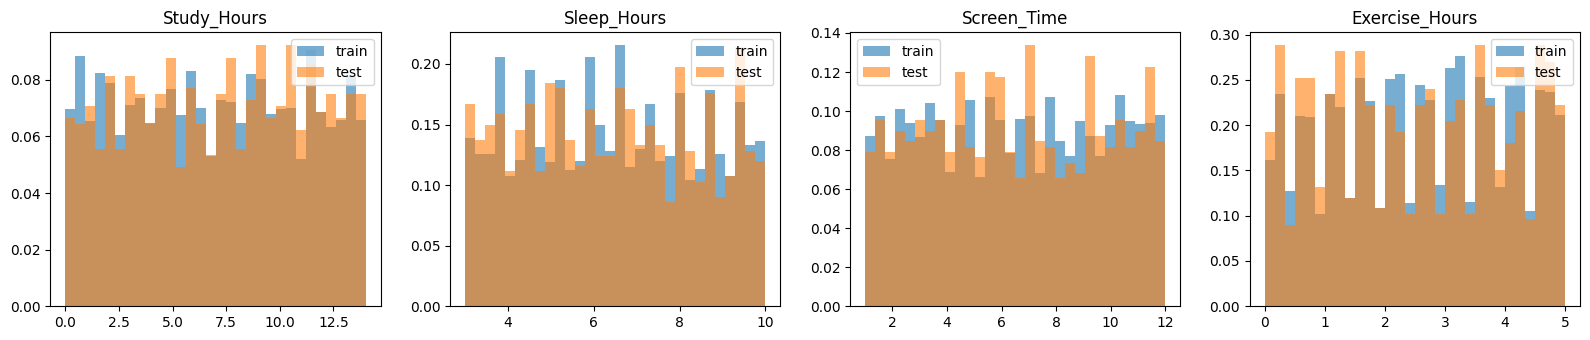

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, NUM_COLS):
    ax.hist(train[c], bins=30, alpha=0.6, density=True, label="train")
    ax.hist(test[c], bins=30, alpha=0.6, density=True, label="test")
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Categorical features

In [ ]:
for c in CAT_COLS:
    tab = pd.DataFrame({
        "train_n": train[c].value_counts().reindex(ORDER[c]),
        "train_%": (train[c].value_counts(normalize=True).reindex(ORDER[c]) * 100).round(1),
        "test_n": test[c].value_counts().reindex(ORDER[c]),
        "test_%": (test[c].value_counts(normalize=True).reindex(ORDER[c]) * 100).round(1),
    })
    print(c)
    display(tab)

Stress_Level


,train_n,train_%,test_n,test_%
Stress_Level,,,,
Low,957,23.9,243,24.3
Medium,1066,26.6,235,23.5
High,973,24.3,275,27.5
Very High,1004,25.1,247,24.7


Diet_Quality


,train_n,train_%,test_n,test_%
Diet_Quality,,,,
Poor,1005,25.1,265,26.5
Average,963,24.1,227,22.7
Good,1025,25.6,242,24.2
Excellent,1007,25.2,266,26.6


## 9. Early signal: features vs target (train only)

In [ ]:
print("Mean of each numeric feature by target class:")
display(train.groupby(TARGET)[NUM_COLS].mean().round(2).loc[ORDER[TARGET]])

anova = {c: stats.f_oneway(*[train.loc[train[TARGET] == k, c] for k in ORDER[TARGET]]).pvalue
         for c in NUM_COLS}
print("ANOVA p-values:")
display(pd.Series(anova, name="p_value").apply(lambda p: f"{p:.2e}").to_frame())

for c in CAT_COLS:
    ct = pd.crosstab(train[c], train[TARGET], normalize="index").round(3)
    display(ct.loc[ORDER[c], ORDER[TARGET]])
    print("chi-square p-value:", f"{stats.chi2_contingency(pd.crosstab(train[c], train[TARGET]))[1]:.2e}")
    print()

Mean of each numeric feature by target class:


,Study_Hours,Sleep_Hours,Screen_Time,Exercise_Hours
Health_Risk,,,,
Low,6.87,6.93,6.09,2.66
Medium,7.03,5.85,7.12,2.41
High,6.90,4.55,7.98,2.24


ANOVA p-values:


,p_value
Study_Hours,5.53e-01
Sleep_Hours,8.09e-127
Screen_Time,1.88e-34
Exercise_Hours,1.61e-09


Health_Risk,Low,Medium,High
Stress_Level,,,
Low,0.868,0.126,0.005
Medium,0.857,0.135,0.008
High,0.448,0.394,0.158
Very High,0.427,0.414,0.158


chi-square p-value: 1.46e-178



Health_Risk,Low,Medium,High
Diet_Quality,,,
Poor,0.512,0.336,0.151
Average,0.707,0.236,0.057
Good,0.716,0.235,0.049
Excellent,0.675,0.256,0.069


chi-square p-value: 6.45e-30



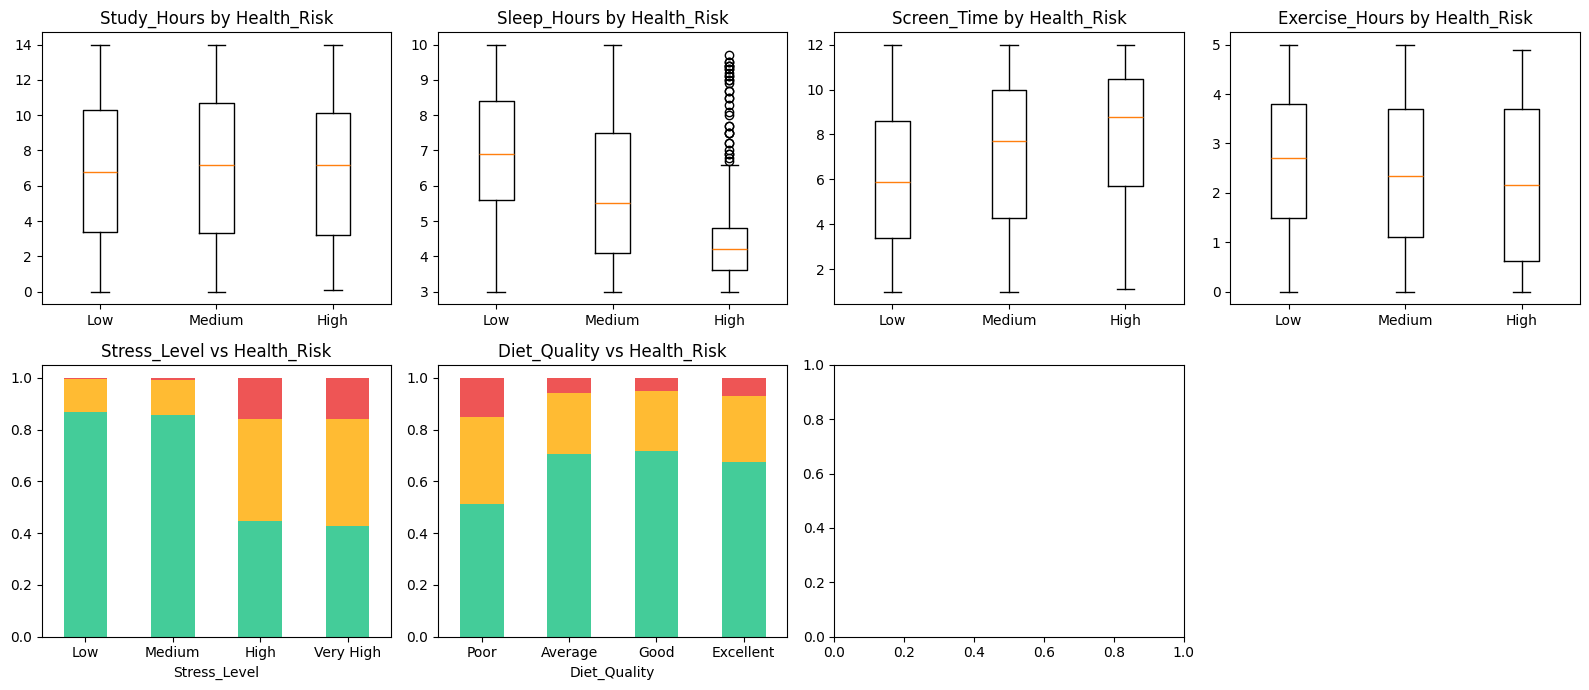

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, c in zip(axes[0], NUM_COLS):
    data = [train.loc[train[TARGET] == k, c] for k in ORDER[TARGET]]
    ax.boxplot(data)
    ax.set_xticklabels(ORDER[TARGET])
    ax.set_title(f"{c} by {TARGET}")

colors = ["#4c9", "#fb3", "#e55"]
for ax, c in zip(axes[1][:2], CAT_COLS):
    pd.crosstab(train[c], train[TARGET], normalize="index").loc[ORDER[c], ORDER[TARGET]] \
        .plot.bar(stacked=True, ax=ax, color=colors, legend=False)
    ax.set_title(f"{c} vs {TARGET}")
    ax.tick_params(axis="x", rotation=0)


axes[1][3].axis("off")
plt.tight_layout()
plt.show()

## 10. Class Overlap

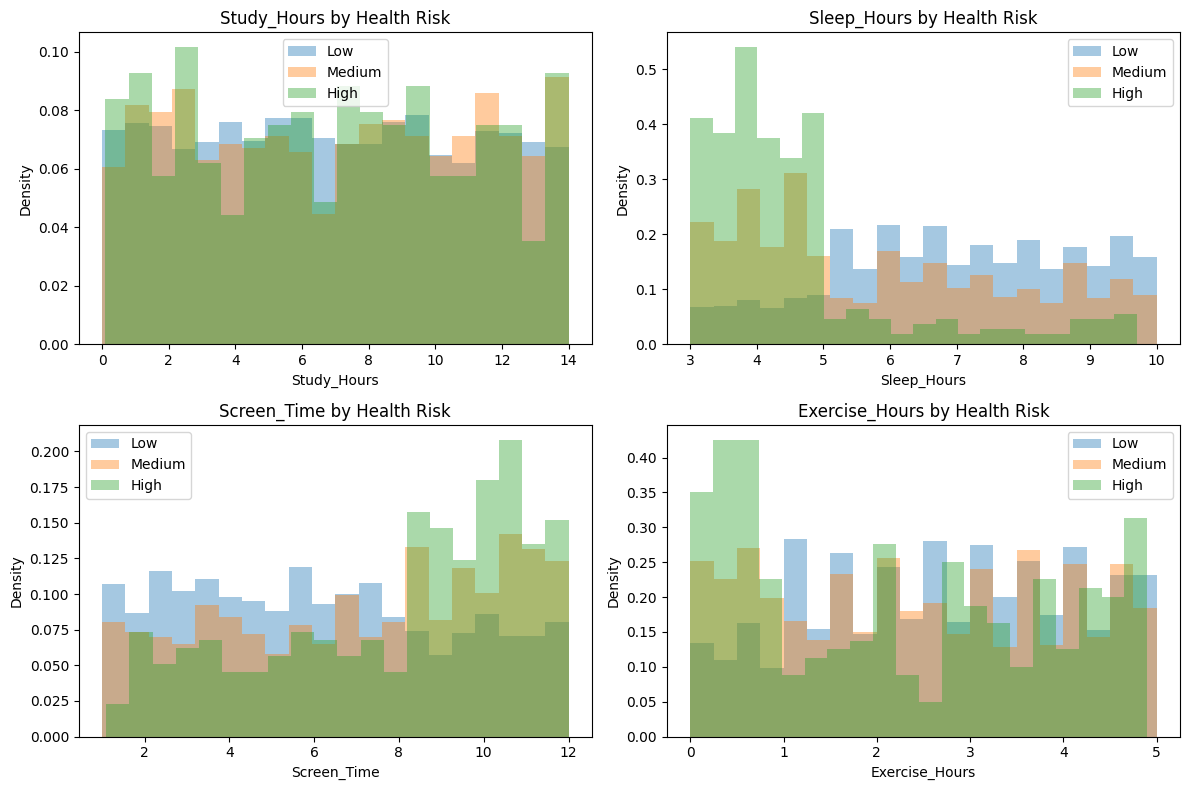

In [ ]:
risk_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, NUM_COLS):
    for risk in risk_order:
        values = train[train[TARGET] == risk][col]

        ax.hist(values, bins=20, density=True,
                alpha=0.4, label=risk)

    ax.set_title(col + " by Health Risk")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


## 11. Pairplot of all numerical features

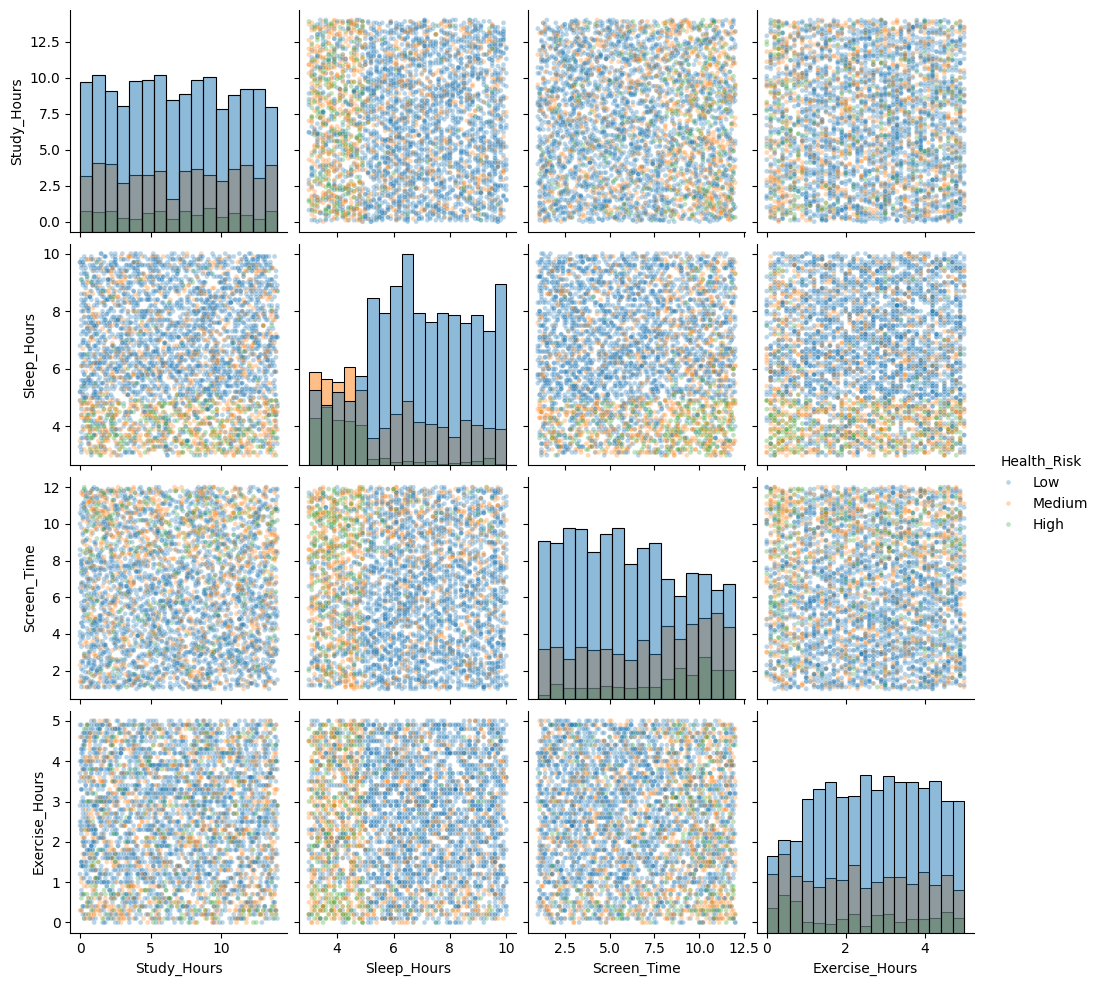

In [ ]:
import seaborn as sns

sns.pairplot(
    train,
    vars=NUM_COLS,
    hue=TARGET,
    hue_order=risk_order,
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 12}
)

plt.show()

## 12. Specific feature scatter plots

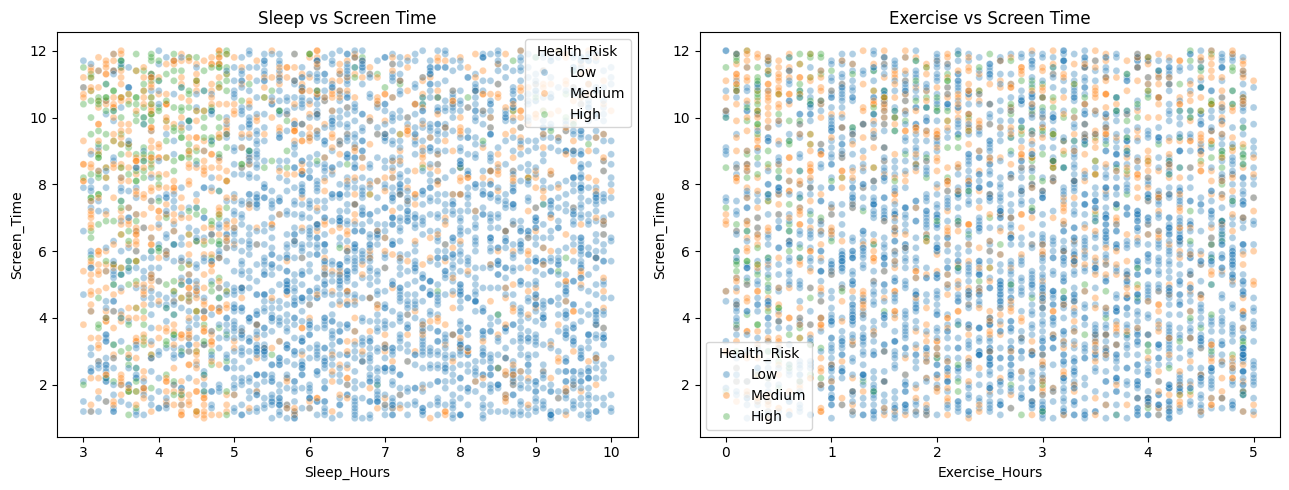

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

## sleep hours vs screen time
sns.scatterplot(
    data=train,
    x="Sleep_Hours",
    y="Screen_Time",
    hue=TARGET,
    hue_order=risk_order,
    alpha=0.35,
    s=25,
    ax=axes[0]
)

axes[0].set_title("Sleep vs Screen Time")

## exercise hours vs screen time
sns.scatterplot(
    data=train,
    x="Exercise_Hours",
    y="Screen_Time",
    hue=TARGET,
    hue_order=risk_order,
    alpha=0.35,
    s=25,
    ax=axes[1]
)

axes[1].set_title("Exercise vs Screen Time")

plt.tight_layout()
plt.show()


## 13. Sleep and stress heatmap

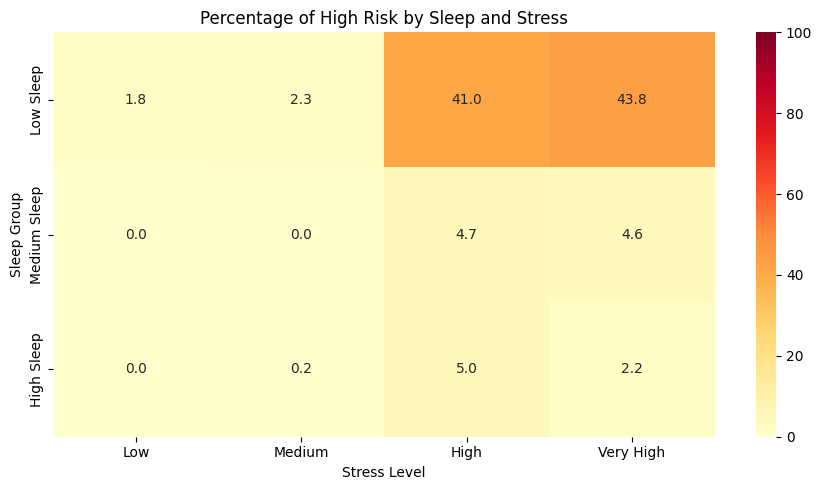

In [ ]:
## group sleep hours
sleep_groups = pd.cut(
    train["Sleep_Hours"],
    bins=[0, 5, 7, 10],
    labels=["Low Sleep", "Medium Sleep", "High Sleep"],
    include_lowest=True
)

## percentage of high risk in each group
heatmap_data = pd.crosstab(
    sleep_groups,
    train["Stress_Level"],
    values=(train[TARGET] == "High").astype(int),
    aggfunc="mean"
) * 100

## putting stress levels in order
heatmap_data = heatmap_data[
    ["Low", "Medium", "High", "Very High"]
]

plt.figure(figsize=(9, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

plt.title("Percentage of High Risk by Sleep and Stress")
plt.xlabel("Stress Level")
plt.ylabel("Sleep Group")

plt.tight_layout()
plt.show()


## 14. Class Overlap w/ PCA

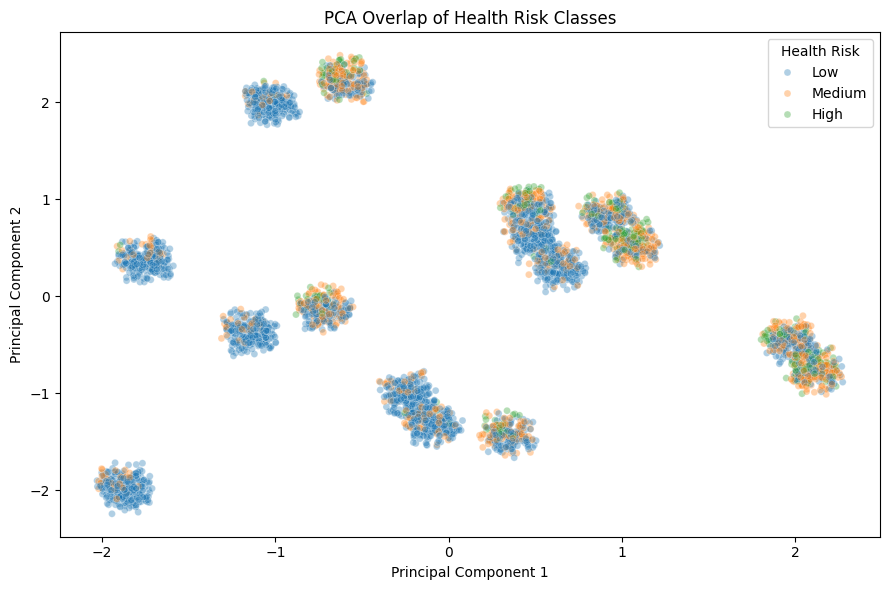

Explained variance by component:
[0.11651813 0.11407558]
Total explained variance:
0.2305937158371391


In [ ]:
## 14. PCA class overlap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

## scale the numerical columns
scaled = StandardScaler().fit_transform(train[NUM_COLS])

scaled = pd.DataFrame(
    scaled,
    columns=NUM_COLS,
    index=train.index
)

## convert categorical columns into numbers
encoded = pd.get_dummies(train[CAT_COLS], dtype=int)

## combine the features
X_pca = pd.concat([scaled, encoded], axis=1)

## scale the combined features
X_scaled = StandardScaler().fit_transform(X_pca)

## reduce features to 2 components
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

## make a dataframe for plotting
pca_df = pd.DataFrame(
    X_reduced,
    columns=["PC1", "PC2"],
    index=train.index
)

pca_df[TARGET] = train[TARGET]

## plot the risk classes
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue=TARGET,
    hue_order=risk_order,
    alpha=0.35,
    s=25
)

plt.title("PCA Overlap of Health Risk Classes")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Health Risk")

plt.tight_layout()
plt.show()

## show how much variance the components explain
print("Explained variance by component:")
print(pca.explained_variance_ratio_)

print("Total explained variance:")
print(pca.explained_variance_ratio_.sum())

## 15. Train/Validation Split And Preprocessing


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Define features and target
TARGET = "Health_Risk"

NUM_COLS = [
    "Study_Hours",
    "Sleep_Hours",
    "Screen_Time",
    "Exercise_Hours"
]

CAT_COLS = ["Stress_Level", "Diet_Quality"]

# Exclude the ID column
X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]

# Split the labeled data: 80% training, 20% validation, w/ stratification
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing for numeric columns
numeric_transformer = StandardScaler()

# Preprocessing for categorical columns
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)

# Check that stratification preserved the class proportions
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation class proportions:")
print(y_val.value_counts(normalize=True).round(3))


preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, NUM_COLS),
    ("cat", categorical_transformer, CAT_COLS)
])

Training set: (3200, 6)
Validation set: (800, 6)

Training class proportions:
Health_Risk
Low       0.652
Medium    0.266
High      0.082
Name: proportion, dtype: float64

Validation class proportions:
Health_Risk
Low       0.652
Medium    0.266
High      0.081
Name: proportion, dtype: float64


## 16. Train Three Baseline Models

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# baseline models
models = {
    "Dummy Classifier": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

results = []
fitted_models = {}
validation_predictions = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)

    fitted_models[name] = pipeline
    validation_predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, y_pred
        ),
        "Macro F1": f1_score(
            y_val, y_pred, average="macro"
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Balanced Accuracy,Macro F1
Model,,,
Dummy Classifier,0.6525,0.3333,0.2632
Logistic Regression,0.7163,0.5498,0.5771
Decision Tree,0.7113,0.6187,0.6160


## 17. Per-Class Performance And Confusion Matrix


Dummy Classifier

Classification report:
              precision    recall  f1-score   support

         Low       0.65      1.00      0.79       522
      Medium       0.00      0.00      0.00       213
        High       0.00      0.00      0.00        65

    accuracy                           0.65       800
   macro avg       0.22      0.33      0.26       800
weighted avg       0.43      0.65      0.52       800

Confusion matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,522,0,0
Actual Medium,213,0,0
Actual High,65,0,0


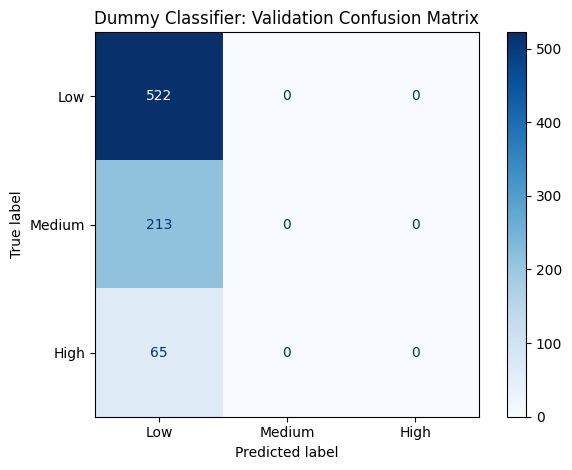


Logistic Regression

Classification report:
              precision    recall  f1-score   support

         Low       0.80      0.89      0.84       522
      Medium       0.48      0.41      0.44       213
        High       0.62      0.35      0.45        65

    accuracy                           0.72       800
   macro avg       0.63      0.55      0.58       800
weighted avg       0.70      0.72      0.70       800

Confusion matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,463,57,2
Actual Medium,114,87,12
Actual High,5,37,23


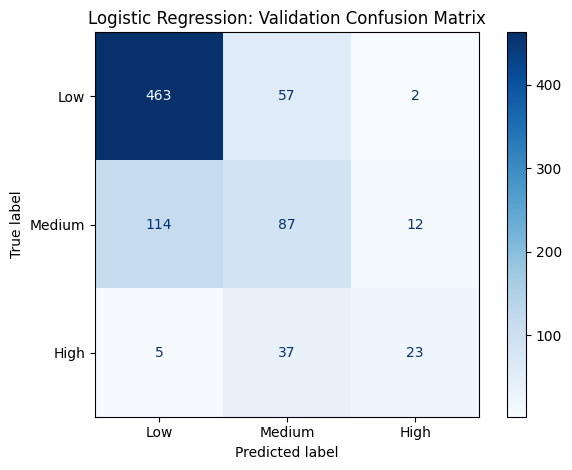


Decision Tree

Classification report:
              precision    recall  f1-score   support

         Low       0.83      0.82      0.82       522
      Medium       0.49      0.50      0.49       213
        High       0.52      0.54      0.53        65

    accuracy                           0.71       800
   macro avg       0.61      0.62      0.62       800
weighted avg       0.71      0.71      0.71       800

Confusion matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,428,86,8
Actual Medium,83,106,24
Actual High,5,25,35


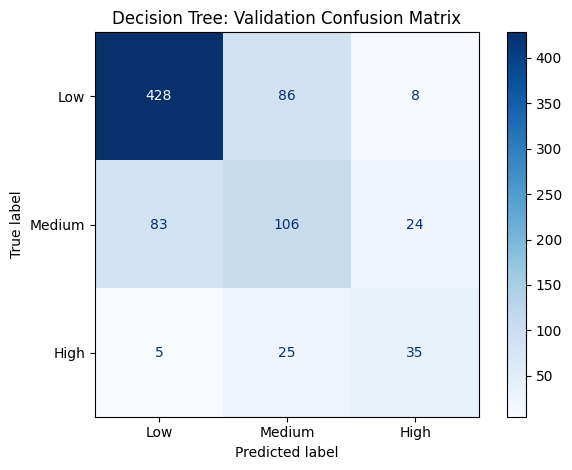

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
risk_order = ["Low", "Medium", "High"]

for name, y_pred in validation_predictions.items():

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nClassification report:")
    print(classification_report(
        y_val,
        y_pred,
        labels=risk_order,
        zero_division=0
    ))

    print("Confusion matrix:")
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=risk_order
    )

    display(pd.DataFrame(
        cm,
        index=[f"Actual {c}" for c in risk_order],
        columns=[f"Predicted {c}" for c in risk_order]
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=risk_order
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"{name}: Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()


###***Section 18: Advanced Models and Evaluation***

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score

# create Random Forest model
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42
)

# use the same preprocessing as our baseline models
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf)
])

# train the model
rf_model.fit(X_train, y_train)

# make predictions
rf_pred = rf_model.predict(X_val)

# evaluate the model
print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_val, rf_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_val, rf_pred), 4))
print("Macro F1:", round(f1_score(y_val, rf_pred, average="macro"), 4))

print("High-risk Recall:", round(
    recall_score(y_val, rf_pred, labels=["High"], average="macro"),
    4
))

Random Forest Results
Accuracy: 0.7612
Balanced Accuracy: 0.6281
Macro F1: 0.648
High-risk Recall: 0.4769


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

# create Extra Trees model
et = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42
)

# use the same preprocessing as previous models
et_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", et)
])

# train the model
et_model.fit(X_train, y_train)

# make predictions
et_pred = et_model.predict(X_val)

# evaluate the model
print("Extra Trees Results")
print("Accuracy:", round(accuracy_score(y_val, et_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_val, et_pred), 4))
print("Macro F1:", round(f1_score(y_val, et_pred, average="macro"), 4))

print("High-risk Recall:", round(
    recall_score(y_val, et_pred, labels=["High"], average="macro"),
    4
))

Extra Trees Results
Accuracy: 0.74
Balanced Accuracy: 0.5981
Macro F1: 0.6207
High-risk Recall: 0.4462


In [ ]:
# compare the two advanced models
results = pd.DataFrame({
    "Model": ["Random Forest", "Extra Trees"],
    "Accuracy": [
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, et_pred)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, rf_pred),
        balanced_accuracy_score(y_val, et_pred)
    ],
    "Macro F1": [
        f1_score(y_val, rf_pred, average="macro"),
        f1_score(y_val, et_pred, average="macro")
    ]
})

# show comparison table
display(results.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Random Forest,0.7612,0.6281,0.6480
1,Extra Trees,0.7400,0.5981,0.6207


Set up cross-validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# create 5 stratified folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# evaluation metrics
scoring = {
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

Random Forest

In [ ]:
# evaluate Random Forest on training data
rf_cv = cross_validate(
    rf_model, X_train, y_train,
    cv=cv, scoring=scoring
)

# show cross-validation results
print("Random Forest Macro F1:", rf_cv["test_macro_f1"].round(4))
print("Mean Macro F1:", round(rf_cv["test_macro_f1"].mean(), 4))
print("Mean Balanced Accuracy:", round(rf_cv["test_balanced_accuracy"].mean(), 4))

Random Forest Macro F1: [0.5824 0.5752 0.6144 0.6642 0.6508]
Mean Macro F1: 0.6174
Mean Balanced Accuracy: 0.5979


Extra Trees

In [ ]:
# evaluate Extra Trees on training data
et_cv = cross_validate(
    et_model, X_train, y_train,
    cv=cv, scoring=scoring
)

# show cross-validation results
print("Extra Trees Macro F1:", et_cv["test_macro_f1"].round(4))
print("Mean Macro F1:", round(et_cv["test_macro_f1"].mean(), 4))
print("Mean Balanced Accuracy:", round(et_cv["test_balanced_accuracy"].mean(), 4))

Extra Trees Macro F1: [0.5296 0.5457 0.5824 0.6387 0.6204]
Mean Macro F1: 0.5834
Mean Balanced Accuracy: 0.5683


### Compare both models

In [ ]:
# compare Random Forest and Extra Trees
cv_results = pd.DataFrame({
    "Model": ["Random Forest", "Extra Trees"],
    "Macro F1": [
        rf_cv["test_macro_f1"].mean(),
        et_cv["test_macro_f1"].mean()
    ],
    "Balanced Accuracy": [
        rf_cv["test_balanced_accuracy"].mean(),
        et_cv["test_balanced_accuracy"].mean()
    ],
    "Macro F1 Std": [
        rf_cv["test_macro_f1"].std(),
        et_cv["test_macro_f1"].std()
    ]
})

display(cv_results.round(4))

,Model,Macro F1,Balanced Accuracy,Macro F1 Std
0,Random Forest,0.6174,0.5979,0.0356
1,Extra Trees,0.5834,0.5683,0.0418


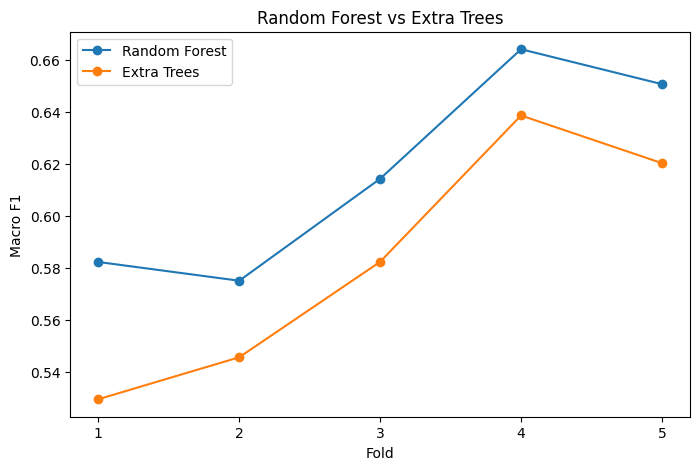

In [ ]:
# compare Macro F1 across five folds
plt.figure(figsize=(8, 5))

plt.plot(range(1, 6), rf_cv["test_macro_f1"],
         marker="o", label="Random Forest")

plt.plot(range(1, 6), et_cv["test_macro_f1"],
         marker="o", label="Extra Trees")

plt.xlabel("Fold")
plt.ylabel("Macro F1")
plt.title("Random Forest vs Extra Trees")
plt.xticks(range(1, 6))
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# parameters to test
rf_params = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}

# search for the best Random Forest settings
rf_search = RandomizedSearchCV(
    rf_model,
    param_distributions=rf_params,
    n_iter=30,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

# tune using training data only
rf_search.fit(X_train, y_train)

# show the best results
print("Best Macro F1:", round(rf_search.best_score_, 4))
print("Best Parameters:")
print(rf_search.best_params_)

Best Macro F1: 0.6798
Best Parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__class_weight': 'balanced'}


In [ ]:
# compare original and tuned cross-validation results
tuning_results = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "Macro F1": [
        rf_cv["test_macro_f1"].mean(),
        rf_search.best_score_
    ]
})

display(tuning_results.round(4))

,Model,Macro F1
0,Original Random Forest,0.6174
1,Tuned Random Forest,0.6798


###Compare PCA and no PCA

In [ ]:
from sklearn.decomposition import PCA
from sklearn.base import clone

# use the best Random Forest settings
best_rf = rf_search.best_estimator_

# create a model with PCA
pca_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("pca", PCA(n_components=0.95)),
    ("model", clone(best_rf.named_steps["model"]))
])

# evaluate both models using the same folds
rf_best_cv = cross_validate(
    best_rf, X_train, y_train,
    cv=cv, scoring=scoring
)

pca_cv = cross_validate(
    pca_model, X_train, y_train,
    cv=cv, scoring=scoring
)

# compare results
pca_results = pd.DataFrame({
    "Model": ["Without PCA", "With PCA"],
    "Macro F1": [
        rf_best_cv["test_macro_f1"].mean(),
        pca_cv["test_macro_f1"].mean()
    ],
    "Balanced Accuracy": [
        rf_best_cv["test_balanced_accuracy"].mean(),
        pca_cv["test_balanced_accuracy"].mean()
    ]
})

display(pca_results.round(4))

,Model,Macro F1,Balanced Accuracy
0,Without PCA,0.6798,0.7101
1,With PCA,0.6041,0.6191


###Permutation importance

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# create a separate split within the training data
X_fit, X_check, y_fit, y_check = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

# train the tuned Random Forest
importance_model = clone(best_rf)
importance_model.fit(X_fit, y_fit)

# measure feature importance
importance = permutation_importance(
    importance_model,
    X_check,
    y_check,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# organize results
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

display(feature_importance.round(4))

,Feature,Importance,Std
4,Stress_Level,0.2087,0.0231
1,Sleep_Hours,0.1872,0.0247
2,Screen_Time,0.0819,0.0138
5,Diet_Quality,0.0534,0.0137
3,Exercise_Hours,0.0428,0.0144
0,Study_Hours,0.0020,0.0100


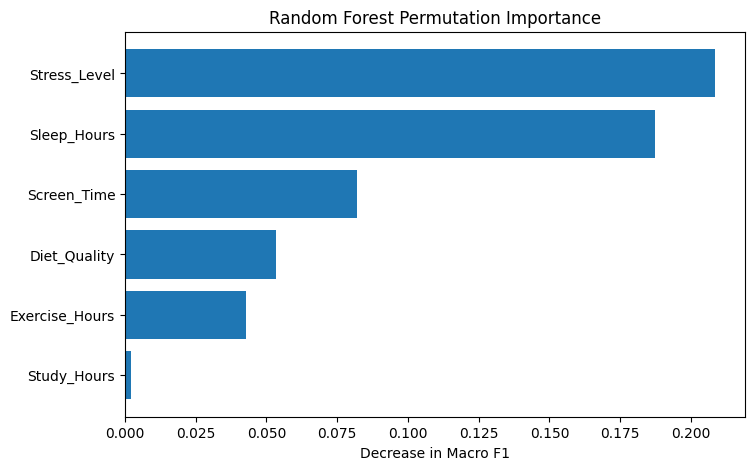

In [ ]:
# plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Decrease in Macro F1")
plt.title("Random Forest Permutation Importance")
plt.gca().invert_yaxis()
plt.show()

### Gradient Bootinng

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

# create Gradient Boosting model
gb = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    random_state=42
)

# use the same preprocessing as previous models
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", gb)
])

# evaluate using training data only
gb_cv = cross_validate(
    gb_model, X_train, y_train,
    cv=cv, scoring=scoring
)

# show results
print("Gradient Boosting Macro F1:", gb_cv["test_macro_f1"].round(4))
print("Mean Macro F1:", round(gb_cv["test_macro_f1"].mean(), 4))
print("Mean Balanced Accuracy:", round(gb_cv["test_balanced_accuracy"].mean(), 4))

Gradient Boosting Macro F1: [0.6082 0.6126 0.6085 0.6689 0.6413]
Mean Macro F1: 0.6279
Mean Balanced Accuracy: 0.6168


In [ ]:
# compare advanced classification models
advanced_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Extra Trees",
        "Tuned Random Forest",
        "Gradient Boosting"
    ],
    "Macro F1": [
        rf_cv["test_macro_f1"].mean(),
        et_cv["test_macro_f1"].mean(),
        rf_search.best_score_,
        gb_cv["test_macro_f1"].mean()
    ],
    "Balanced Accuracy": [
        rf_cv["test_balanced_accuracy"].mean(),
        et_cv["test_balanced_accuracy"].mean(),
        rf_best_cv["test_balanced_accuracy"].mean(),
        gb_cv["test_balanced_accuracy"].mean()
    ]
})

display(advanced_results.round(4))

,Model,Macro F1,Balanced Accuracy
0,Random Forest,0.6174,0.5979
1,Extra Trees,0.5834,0.5683
2,Tuned Random Forest,0.6798,0.7101
3,Gradient Boosting,0.6279,0.6168


### SVM

In [ ]:
from sklearn.svm import SVC

# create nonlinear SVM
svm = SVC(
    kernel="rbf",
    C=1.0,
    class_weight="balanced",
    random_state=42
)

# use the same preprocessing as previous models
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", svm)
])

# evaluate using training data only
svm_cv = cross_validate(
    svm_model, X_train, y_train,
    cv=cv, scoring=scoring
)

# show results
print("SVM Macro F1:", svm_cv["test_macro_f1"].round(4))
print("Mean Macro F1:", round(svm_cv["test_macro_f1"].mean(), 4))
print("Mean Balanced Accuracy:", round(svm_cv["test_balanced_accuracy"].mean(), 4))

SVM Macro F1: [0.5979 0.5975 0.5887 0.6164 0.6335]
Mean Macro F1: 0.6068
Mean Balanced Accuracy: 0.6737


In [ ]:
# compare all advanced classifiers
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Extra Trees",
        "Tuned Random Forest",
        "Gradient Boosting",
        "SVM"
    ],
    "Macro F1": [
        rf_cv["test_macro_f1"].mean(),
        et_cv["test_macro_f1"].mean(),
        rf_search.best_score_,
        gb_cv["test_macro_f1"].mean(),
        svm_cv["test_macro_f1"].mean()
    ],
    "Balanced Accuracy": [
        rf_cv["test_balanced_accuracy"].mean(),
        et_cv["test_balanced_accuracy"].mean(),
        rf_best_cv["test_balanced_accuracy"].mean(),
        gb_cv["test_balanced_accuracy"].mean(),
        svm_cv["test_balanced_accuracy"].mean()
    ]
})

display(model_comparison.round(4))

,Model,Macro F1,Balanced Accuracy
0,Random Forest,0.6174,0.5979
1,Extra Trees,0.5834,0.5683
2,Tuned Random Forest,0.6798,0.7101
3,Gradient Boosting,0.6279,0.6168
4,SVM,0.6068,0.6737


In [ ]:
from sklearn.model_selection import GridSearchCV

# parameters to test
svm_params = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

# tune SVM using training data only
svm_search = GridSearchCV(
    svm_model,
    param_grid=svm_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

svm_search.fit(X_train, y_train)

print("Best SVM Macro F1:", round(svm_search.best_score_, 4))
print("Best Parameters:", svm_search.best_params_)

Best SVM Macro F1: 0.607
Best Parameters: {'model__C': 100, 'model__gamma': 0.01}


In [ ]:
# compare tuned classifiers
tuned_results = pd.DataFrame({
    "Model": ["Tuned Random Forest", "Tuned SVM"],
    "Best CV Macro F1": [
        rf_search.best_score_,
        svm_search.best_score_
    ]
})

display(tuned_results.round(4))

,Model,Best CV Macro F1
0,Tuned Random Forest,0.6798
1,Tuned SVM,0.6070


###Final predictions and metrics

In [ ]:
# select the tuned Random Forest
final_model = rf_search.best_estimator_

# predict the validation data
final_pred = final_model.predict(X_val)

# calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_val, final_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_val, final_pred), 4))
print("Macro F1:", round(f1_score(y_val, final_pred, average="macro"), 4))

print("High-risk Recall:", round(
    recall_score(y_val, final_pred, labels=["High"], average="macro"),
    4
))

Accuracy: 0.76
Balanced Accuracy: 0.7448
Macro F1: 0.7034
High-risk Recall: 0.8154


In [ ]:
# examine precision, recall and F1 for each risk category
print(classification_report(
    y_val,
    final_pred,
    labels=["Low", "Medium", "High"],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

         Low     0.8933    0.8180    0.8540       522
      Medium     0.5541    0.6009    0.5766       213
        High     0.5824    0.8154    0.6795        65

    accuracy                         0.7600       800
   macro avg     0.6766    0.7448    0.7034       800
weighted avg     0.7777    0.7600    0.7660       800



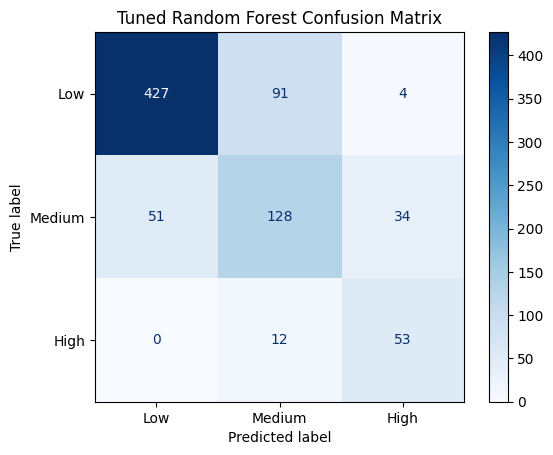

In [ ]:
# show correct and incorrect predictions for each class
ConfusionMatrixDisplay.from_predictions(
    y_val,
    final_pred,
    labels=["Low", "Medium", "High"],
    cmap="Blues"
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

### Compare Baseline and Final Model

In [ ]:
# get the original Decision Tree predictions
baseline_pred = validation_predictions["Decision Tree"]

# compare the baseline and final model
final_comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Tuned Random Forest"],

    "Accuracy": [
        accuracy_score(y_val, baseline_pred),
        accuracy_score(y_val, final_pred)
    ],

    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, baseline_pred),
        balanced_accuracy_score(y_val, final_pred)
    ],

    "Macro F1": [
        f1_score(y_val, baseline_pred, average="macro"),
        f1_score(y_val, final_pred, average="macro")
    ],

    "High-risk Recall": [
        recall_score(y_val, baseline_pred, labels=["High"], average="macro"),
        recall_score(y_val, final_pred, labels=["High"], average="macro")
    ]
})

display(final_comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1,High-risk Recall
0,Decision Tree,0.7113,0.6187,0.6160,0.5385
1,Tuned Random Forest,0.7600,0.7448,0.7034,0.8154


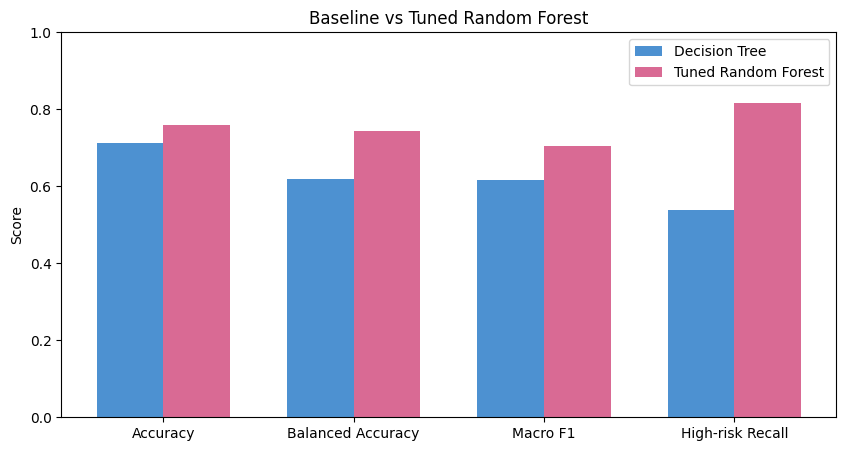

In [ ]:
# compare baseline and final model performance
metrics = ["Accuracy", "Balanced Accuracy", "Macro F1", "High-risk Recall"]

baseline = [0.7113, 0.6187, 0.6160, 0.5385]

final = [
    accuracy_score(y_val, final_pred),
    balanced_accuracy_score(y_val, final_pred),
    f1_score(y_val, final_pred, average="macro"),
    recall_score(y_val, final_pred, labels=["High"], average="macro")
]

# create grouped bar chart
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, baseline, width,
        label="Decision Tree", color="#4D91D1")

plt.bar(x + width/2, final, width,
        label="Tuned Random Forest", color="#D96A94")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Baseline vs Tuned Random Forest")
plt.legend()

plt.show()

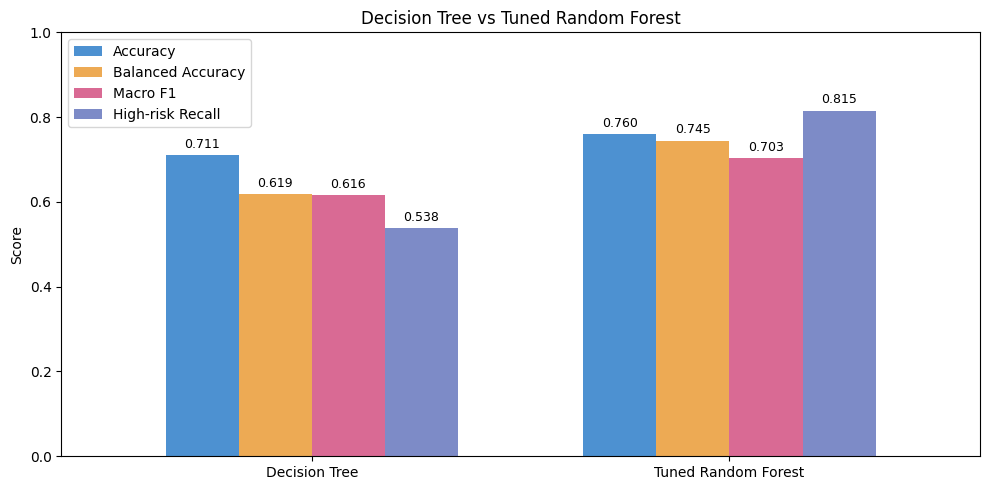

In [ ]:
# prepare model comparison data
graph_data = final_comparison.set_index("Model")

# create grouped bar chart
ax = graph_data.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#4D91D1", "#EDAA54", "#D96A94", "#7D8BC7"],
    width=0.7
)

# add score labels
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

plt.title("Decision Tree vs Tuned Random Forest")
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

###Final Test Predictions

In [ ]:
from sklearn.base import clone

# use the selected Random Forest model
test_model = clone(rf_search.best_estimator_)

# use the same features as the original models
X_full = train[X_train.columns]
y_full = train["Health_Risk"]

# retrain using all labeled students
test_model.fit(X_full, y_full)

# predict the unlabeled students
X_test = test[X_train.columns]
test_pred = test_model.predict(X_test)

# create final predictions table
final_predictions = pd.DataFrame({
    "id": test["id"],
    "Health_Risk": test_pred
})

display(final_predictions.head())
print("Total predictions:", len(final_predictions))

,id,Health_Risk
0,3,Low
1,4,Low
2,5,High
3,9,Medium
4,16,Low


Total predictions: 1000


In [ ]:
# count predicted students in each risk category
prediction_counts = final_predictions["Health_Risk"].value_counts()

# show counts and percentages
prediction_summary = pd.DataFrame({
    "Count": prediction_counts,
    "Percentage": (
        prediction_counts / len(final_predictions) * 100
    ).round(2)
})

display(prediction_summary)

,Count,Percentage
Health_Risk,,
Low,554,55.4
Medium,339,33.9
High,107,10.7


### 18.15 Final Research Conclusion and Limitations

#### Conclusion

The tuned Random Forest was our best model, achieving:

- **Accuracy:** 76.00%
- **Balanced Accuracy:** 74.48%
- **Macro F1:** 0.7034
- **High-risk Recall:** 81.54%

The model correctly identified **53 of 65 High-risk students**, compared with 35 for the baseline.

Stress and sleep were the strongest predictors. PCA did not improve performance.

#### Limitations

- Medium-risk students were the hardest to classify.
- High-risk precision was only 58.24%.
- The dataset contains only six predictors.
- The validation set was examined during exploration.
- Test predictions cannot be verified without true labels.
- Predictive relationships do not prove causation.

#### Future Improvements

- Test on larger, independent datasets.
- Explore additional lifestyle factors.
- Improve Medium-risk classification.

#### Final Conclusion

**Yes, lifestyle factors can help predict student health risk.** The tuned Random Forest improved overall performance and High-risk detection, but further validation is needed.